Dataset:
   Study_Hours  Marks
0            1     15
1            2     20
2            3     28
3            4     40
4            5     55
5            6     68
6            7     78
7            8     86
8            9     92
9           10     96

Actual Marks:
[92 20]

Predicted Marks:
[91.57758621 22.42241379]

Mean Squared Error: 3.0232609988109873
R2 Score: 0.9976672368836335


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


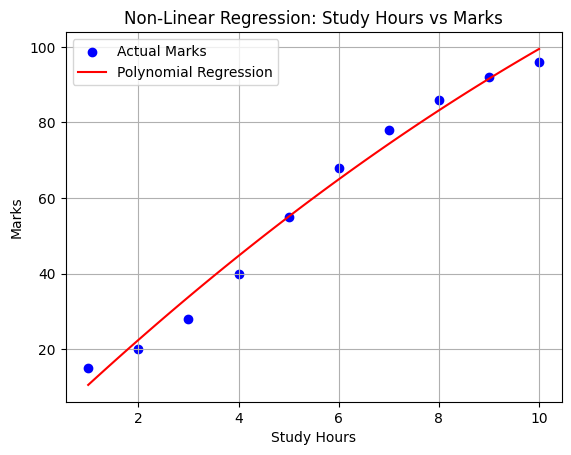

In [ ]:
#AP24110011180
# NON-LINEAR REGRESSION
# Student Study Hours vs Marks

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Step 2: Create dataset
data = {
    'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks': [15, 20, 28, 40, 55, 68, 78, 86, 92, 96]
}

df = pd.DataFrame(data)
print("Dataset:")
print(df)

# Step 3: Separate input and output
X = df[['Study_Hours']]
y = df['Marks']

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Convert input into polynomial features
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Step 6: Train the model
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Step 7: Predict test values
y_pred = model.predict(X_test_poly)

print("\nActual Marks:")
print(y_test.values)

print("\nPredicted Marks:")
print(y_pred)

# Step 8: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Squared Error:", mse)
print("R2 Score:", r2)

# Step 9: Plot the regression curve
X_curve = np.linspace(
    X['Study_Hours'].min(),
    X['Study_Hours'].max(),
    100
).reshape(-1, 1)

X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)

plt.scatter(X, y, color='blue', label='Actual Marks')
plt.plot(X_curve, y_curve, color='red',
         label='Polynomial Regression')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.title('Non-Linear Regression: Study Hours vs Marks')
plt.legend()
plt.grid(True)
plt.show()

# Step 10: Predict marks for new study hours
hours = float(input("Enter study hours: "))
new_data = pd.DataFrame({'Study_Hours': [hours]})
new_data_poly = poly.transform(new_data)

prediction = model.predict(new_data_poly)
print("Predicted Marks:", round(prediction[0], 2))
#AP24110011180
